# 07 · Exploratory baseline: VIIRS → Aqua MODIS scale

**This notebook keeps the baseline of the earlier approach. It is not the final common index.**

Direction of the fit: weekly national counts of **Suomi NPP VIIRS** as input and detections reported by **Aqua MODIS** as reference. The MODIS → VIIRS direction was not trained here; inverting the factors is not the same as training and validating that other model.

A global factor and regularized monthly factors were compared. The selected seasonal baseline is kept with its executed results so it can later be compared with the common index.

- Development: 2013–2021.
- Validation: 2022–2023.
- Test 2024–2025: not evaluated in this notebook.
- Scope: all of Peru per week; not a validated correction of each cell or of NOAA-20/21.
- The original records are kept. Coverage/clouds are not corrected and missed fires are not recovered.

Run after 01 and 02. Dependencies: pandas, numpy and matplotlib. The progress percentages saved in the results belong to the earlier experimental plan, not to the progress of the common index.

In [1]:
from pathlib import Path
import os
import json
import hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
ROOT = Path.cwd().resolve()
if ROOT.name in {'notebooks', 'validacion'}:
    ROOT = ROOT.parent
ARTIFACTS = Path(os.environ.get('FIRMS_ARTIFACTS_DIR', str(ROOT / 'artifacts')))
SOURCE = ARTIFACTS / '03_espacio_tiempo' / 'conteos_semanales_10km.csv.gz'
OUT = ARTIFACTS / '08_armonizacion'
OUT.mkdir(parents=True, exist_ok=True)

## 1. Contract and data
The counts of ALL the downloaded cells are added, not only co-detections.
Aqua and Suomi NPP, SP, type=0, without a confidence filter, according to earlier decisions.
The 10 km grid is only the input partition: the national sum does not depend
on that size because each detection belongs to one cell.
A platform without records in a week stays NA, not a confirmed zero.

In [2]:
def load_weekly(path):
    parts = []
    columns = ['week_start_utc', 'platform', 'split_proposed', 'n_detections']
    for chunk in pd.read_csv(path, usecols=columns, chunksize=50000):
        chunk = chunk.loc[chunk.split_proposed.isin(['development', 'validation'])]
        if len(chunk):
            parts.append(chunk.groupby(['week_start_utc', 'platform']).n_detections.sum())
    combined = pd.concat(parts).groupby(level=[0, 1]).sum()
    weekly = combined.unstack('platform')
    weekly.index = pd.to_datetime(weekly.index, utc=True)
    # Calendarios de semanas completas dentro de cada bloque; no se rellenan ceros.
    train_index = pd.date_range('2013-01-07', '2021-12-20', freq='W-MON', tz='UTC')
    val_index = pd.date_range('2022-01-03', '2023-12-25', freq='W-MON', tz='UTC')
    weekly = weekly.reindex(train_index.append(val_index)).rename_axis('week_start_utc')
    weekly['split'] = np.where(weekly.index.year <= 2021, 'development', 'validation')
    weekly['month'] = (weekly.index + pd.Timedelta(days=3)).month
    assert weekly.index.max() < pd.Timestamp('2024-01-01', tz='UTC')
    assert weekly.index.is_unique and weekly.index.dayofweek.min() == 0
    return weekly


weekly = load_weekly(SOURCE)
paired = weekly[['Aqua', 'Suomi-NPP']].notna().all(axis=1)
train = weekly.loc[weekly.split.eq('development') & paired].copy()
validation = weekly.loc[weekly.split.eq('validation') & paired].copy()
missing = weekly.loc[~paired].copy()
display(weekly.groupby('split')[['Aqua', 'Suomi-NPP']].count().rename(columns={
    'Aqua': 'weeks_with_aqua_records', 'Suomi-NPP': 'weeks_with_viirs_records'}))
print('Semanas comparables: desarrollo', len(train), '| validación', len(validation))
print('Semanas sin registros de una o ambas plataformas:', len(missing))
display(missing)

platform,weeks_with_aqua_records,weeks_with_viirs_records
split,,
development,468,468
validation,103,103


Semanas comparables: desarrollo 468 | validación 102
Semanas sin registros de una o ambas plataformas: 2


platform,Aqua,Suomi-NPP,split,month
week_start_utc,,,,
2022-04-04 00:00:00+00:00,NaN,98.0,validation,4
2022-08-01 00:00:00+00:00,158.0,NaN,validation,8


Weeks without records are not used to compute errors; they stay in the
export with an unknown-coverage label. Even with detections
from both sensors, it is not known whether the observation opportunities were equal.
This evaluation is conditioned on weeks with positive national records from both.

## 2. Candidates defined before looking at the validation error
Identity: VIIRS without correction (comparison control).
Global: VIIRS multiplied by sum(Aqua)/sum(VIIRS) of the development period.
Seasonal: one factor per month of the week's midpoint, shrunk towards
the global one. The shrinkage uses an exposure equivalent to eight median VIIRS weeks
of development; it is a fixed hyperparameter, not chosen with the test.
Seasonal is chosen only if it reduces the validation MAE by at least 2 % against the global one.
Values are not rounded and no new points are generated: they are aggregated estimates.

In [3]:
def fit_factors(development, prior_weeks=8):
    if development[['Aqua', 'Suomi-NPP']].isna().any().any():
        raise ValueError('No ajustar con valores ausentes.')
    if (development['Suomi-NPP'] <= 0).any() or (development['Aqua'] < 0).any():
        raise ValueError('Conteos de desarrollo inválidos.')
    global_factor = float(development.Aqua.sum() / development['Suomi-NPP'].sum())
    exposure = float(prior_weeks * development['Suomi-NPP'].median())
    groups = development.groupby('month')[['Aqua', 'Suomi-NPP']].sum().reindex(range(1, 13))
    groups['factor'] = (groups.Aqua + global_factor*exposure) / (groups['Suomi-NPP']+exposure)
    groups['factor'] = groups.factor.fillna(global_factor)
    return {'global_factor': global_factor, 'prior_weeks': prior_weeks,
            'prior_viirs_exposure': exposure,
            'monthly_factors': {int(k): float(v) for k, v in groups.factor.items()}}


def predictions(frame, model):
    x = frame['Suomi-NPP'].astype(float)
    month_factors = frame.month.map({int(k): v for k, v in model['monthly_factors'].items()})
    return pd.DataFrame({'identity': x, 'global': x*model['global_factor'],
                         'seasonal': x*month_factors}, index=frame.index)


def metrics(reference, estimate):
    y, p = np.asarray(reference, dtype=float), np.asarray(estimate, dtype=float)
    if not len(y) or not np.isfinite(y).all() or not np.isfinite(p).all():
        raise ValueError('Evaluación requiere pares finitos y no vacíos.')
    err = p-y
    return {'weeks': len(y), 'mae': float(np.mean(np.abs(err))),
            'rmse': float(np.sqrt(np.mean(err**2))),
            'wape_percent': float(100*np.abs(err).sum()/y.sum()),
            'aggregate_bias_percent': float(100*err.sum()/y.sum())}


model = fit_factors(train)
score_rows = []
for label, frame in [('development', train), ('validation', validation)]:
    pred = predictions(frame, model)
    for method in pred:
        score_rows.append({'split': label, 'method': method, **metrics(frame.Aqua, pred[method])})
scores = pd.DataFrame(score_rows)
val_scores = scores[scores.split.eq('validation')].set_index('method')
seasonal_gain = 1 - val_scores.loc['seasonal', 'mae']/val_scores.loc['global', 'mae']
selected = 'seasonal' if seasonal_gain >= .02 else 'global'
display(scores.round(3))
print('Candidato elegido:', selected, '| mejora MAE estacional/global:', round(seasonal_gain*100, 2), '%')
display(pd.Series(model['monthly_factors'], name='VIIRS_to_Aqua_factor').to_frame())

,split,method,weeks,mae,rmse,wape_percent,aggregate_bias_percent
0,development,identity,468,1117.701,1966.081,499.856,499.856
1,development,global,468,56.640,137.575,25.331,-0.000
2,development,seasonal,468,44.808,127.341,20.039,1.167
3,validation,identity,102,1335.912,2164.661,490.614,489.080
4,validation,global,102,55.872,101.583,20.519,-1.796
5,validation,seasonal,102,45.939,86.882,16.871,-0.916


Candidato elegido: seasonal | mejora MAE estacional/global: 17.78 %


,VIIRS_to_Aqua_factor
1,0.126378
2,0.121897
3,0.118361
4,0.129348
5,0.127152
6,0.135601
7,0.153143
8,0.180532
9,0.196660
10,0.154548


MAE is expressed in weekly reference detections. WAPE divides the total absolute
error by the total Aqua count. Positive bias means overestimation
of Aqua. These are errors against a sensor, not errors against the real fire.
The factors were fitted only on development. Selection by validation can
produce optimism: that is why the final 2024–2025 test is still missing.

## 3. Estimates and analysis by validation segments
The original Aqua and VIIRS values are preserved. Where VIIRS is missing there is no estimate.
If Aqua is missing but VIIRS exists, there may be an estimate, but no verifiable error.
The uncertainty is not calibrated yet; no misleading intervals are published.

In [4]:
estimates = predictions(weekly, model)
result = weekly.copy()
result['aqua_equivalent_estimate'] = estimates[selected]
result['method'] = selected
result['reference_available'] = result.Aqua.notna()
result['viirs_available'] = result['Suomi-NPP'].notna()
result['evaluation_eligible'] = paired
result['observational_coverage'] = 'unknown'
result['uncertainty_status'] = 'not_calibrated'
result['estimate_minus_aqua'] = result.aqua_equivalent_estimate - result.Aqua
slices = []
for year, group in result.loc[result.split.eq('validation') & paired].groupby(result.loc[result.split.eq('validation') & paired].index.year):
    slices.append({'segment': f'year_{year}', **metrics(group.Aqua, group.aqua_equivalent_estimate)})
for label, months in [('peak_aug_oct', [8,9,10]), ('other_months', [1,2,3,4,5,6,7,11,12])]:
    group = result.loc[result.split.eq('validation') & paired & result.month.isin(months)]
    slices.append({'segment': label, **metrics(group.Aqua, group.aqua_equivalent_estimate)})
slices = pd.DataFrame(slices)
display(slices.round(3))
assert result.loc[~result.viirs_available, 'aqua_equivalent_estimate'].isna().all()
assert result.aqua_equivalent_estimate.dropna().ge(0).all()
assert result.index.max().year == 2023
result.to_csv(OUT / 'serie_nacional_semanal_provisional_2013_2023.csv')
scores.to_csv(OUT / 'metricas_desarrollo_validacion.csv', index=False)
slices.to_csv(OUT / 'errores_segmentos_validacion.csv', index=False)
missing.to_csv(OUT / 'semanas_sin_registros_pareados.csv')

,segment,weeks,mae,rmse,wape_percent,aggregate_bias_percent
0,year_2022,50,51.306,98.241,16.942,-4.796
1,year_2023,52,40.778,74.340,16.786,3.734
2,peak_aug_oct,25,104.104,142.732,12.669,1.998
3,other_months,77,27.054,58.179,28.809,-9.196


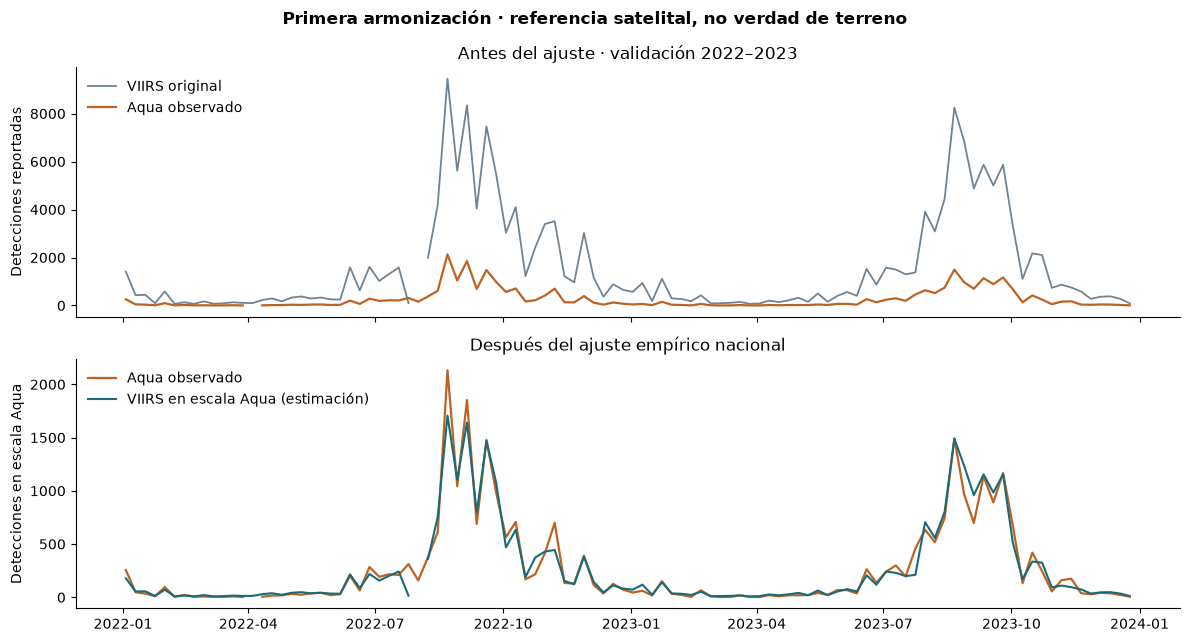

In [5]:
plt.rcParams.update({'font.family':'DejaVu Sans','font.size':10})
fig, axes = plt.subplots(2,1,figsize=(12,6.5),sharex=True)
v = result[result.split.eq('validation')]
axes[0].plot(v.index, v['Suomi-NPP'], color='#718390', label='VIIRS original', linewidth=1.3)
axes[0].plot(v.index, v.Aqua, color='#bd6223', label='Aqua observado', linewidth=1.6)
axes[0].set(ylabel='Detecciones reportadas', title='Antes del ajuste · validación 2022–2023')
axes[1].plot(v.index, v.Aqua, color='#bd6223', label='Aqua observado', linewidth=1.6)
axes[1].plot(v.index, v.aqua_equivalent_estimate, color='#186b77', label='VIIRS en escala Aqua (estimación)', linewidth=1.5)
axes[1].set(ylabel='Detecciones en escala Aqua', title='Después del ajuste empírico nacional')
for ax in axes:
    ax.legend(frameon=False,loc='upper left');ax.spines[['top','right']].set_visible(False)
fig.suptitle('Primera armonización · referencia satelital, no verdad de terreno',fontweight='bold')
fig.tight_layout()
plt.show()

The panels use different vertical scales to show the detail of the fit.
Gaps are kept as NA; they are not interpreted as zero fire.
The fit is expected to bring magnitudes closer, not to remove real differences
in sensitivity or recover locations that MODIS could not detect.

## 4. Model checks and contract
Reproducible serialization, non-negative predictions, held-out dates outside
fitting/evaluation and explicit preservation of missing values.

In [6]:
restored = json.loads(json.dumps(model))
pd.testing.assert_frame_equal(predictions(validation, model), predictions(validation, restored))
assert metrics([1,2,3],[1,2,3])['mae'] == 0
assert (train.index < validation.index.min()).all()
assert not weekly.index.year.isin([2024,2025]).any()
assert np.isclose(predictions(train, model)['global'].sum(), train.Aqua.sum())
contract = {
    'progress_percent':80, 'status':'provisional_empirical_national_baseline',
    'reference':'Aqua MODIS reported detections, not true fire counts',
    'spatial_scope':'Peru national totals; NOT cell-level correction',
    'time_scope':'Complete UTC Monday-Sunday weeks; month at Thursday midpoint',
    'training_years':[2013,2021], 'validation_years':[2022,2023],
    'test_years_reserved':[2024,2025], 'test_evaluated':False,
    'selected_method':selected, 'selection_rule':'seasonal only if validation MAE improves >=2% over global',
    'seasonal_mae_gain_vs_global_percent':float(seasonal_gain*100),
    'model':model, 'training_pairs':len(train), 'validation_pairs':len(validation),
    'excluded_nonpaired_weeks':len(missing),
    'validation_metrics':val_scores.loc[selected].to_dict(),
    'uncertainty_calibrated':False, 'coverage_corrected':False,
    'raw_points_modified':False, 'missing_values_imputed':False,
    'pending':['final heldout evaluation','uncertainty calibration','historical sensor backbone and full export'],
}
(OUT/'modelo_provisional.json').write_text(json.dumps(contract,ensure_ascii=False,indent=2),encoding='utf-8')
print('Baseline implementado y validado preliminarmente. Prueba final pendiente de revisión humana.')

Baseline implementado y validado preliminarmente. Prueba final pendiente de revisión humana.


## Limitations and next review point
This model must not be applied automatically to cells, departments or other
VIIRS platforms. It was evaluated on weeks with records from both sensors.
Unknown coverage, changes of overpass times and differences in sensitivity remain.
A good national error can hide local errors. The geographic review of
Curimaná does not set factors and was not used to choose the model.
A harmonized 2000–2026 history and a NOAA-20/21 calibration are not offered yet.
Before using 2024–2025: review these results, fix the method for good
and define empirical intervals with 2022–2023. Then measure the test only once.